contra_motor : Full Correlation Effective FDR = 0.000967305088024763
contra_motor : Partial Correlation Effective FDR = 0.001941672168071143
Left : Full Correlation Effective FDR = 0.001585917056537943
Left : Partial Correlation Effective FDR = 0.012353304508956145
Right : Full Correlation Effective FDR = 0.0018862230270107138
Right : Partial Correlation Effective FDR = 0.02376425855513308
Verbal : Full Correlation Effective FDR = 0.0021208907741251328
Verbal : Partial Correlation Effective FDR = 0.00528597103287874
LanguageReception : Full Correlation Effective FDR = 0.004929265046581555
LanguageReception : Partial Correlation Effective FDR = 0.02288329519450801
Cognitive_Behavioral : Full Correlation Effective FDR = 0.02942907592701589
Cognitive_Behavioral : Partial Correlation Effective FDR = 0.5617977528089888


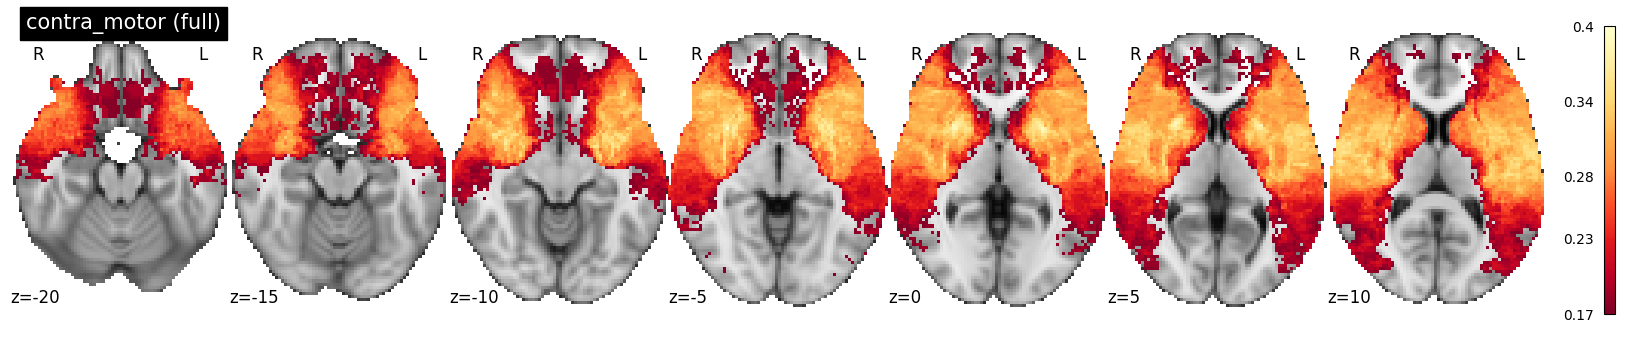

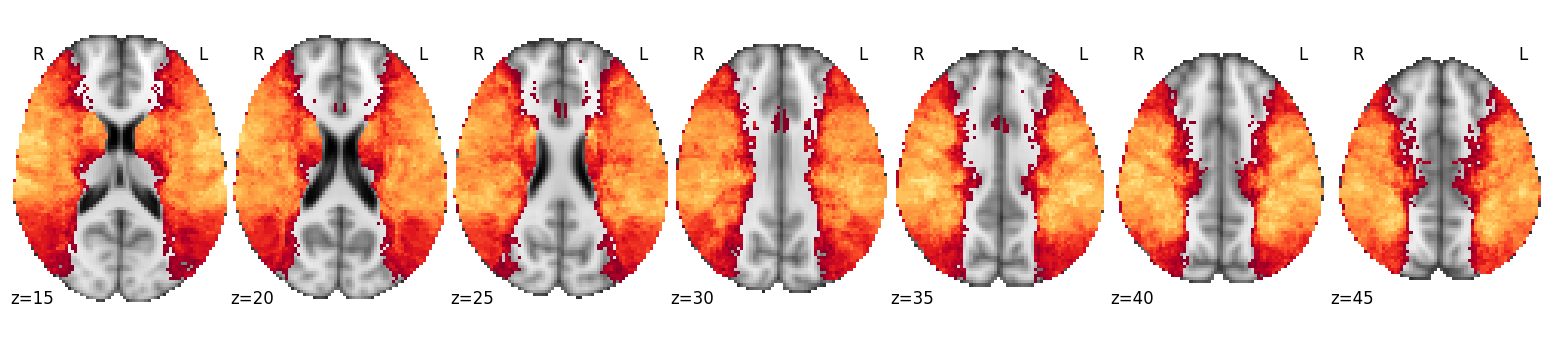

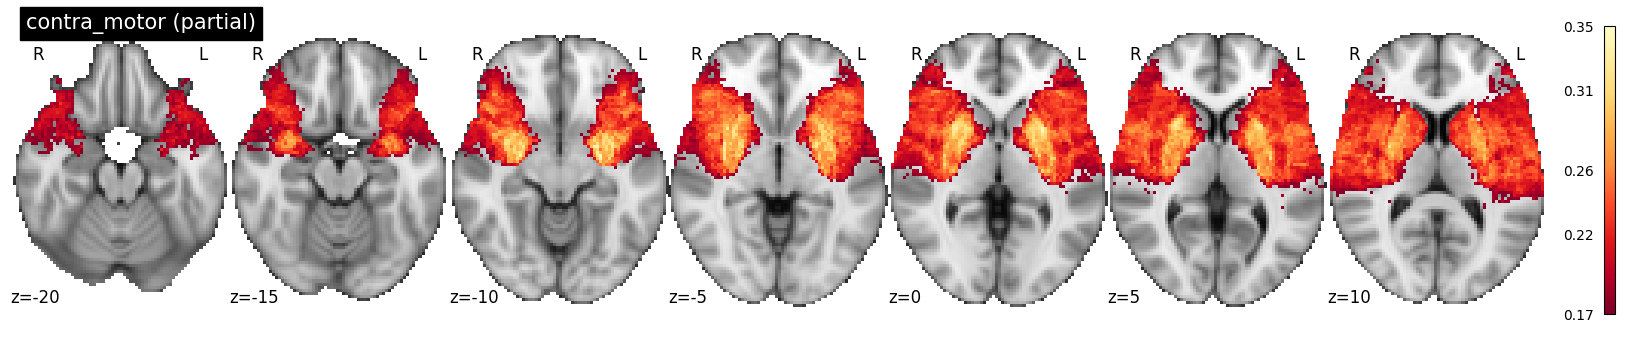

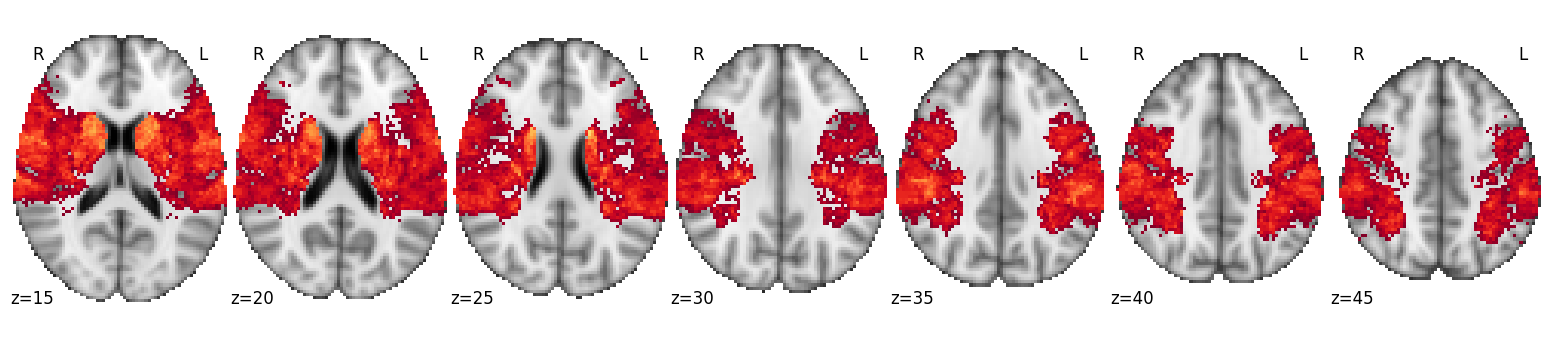

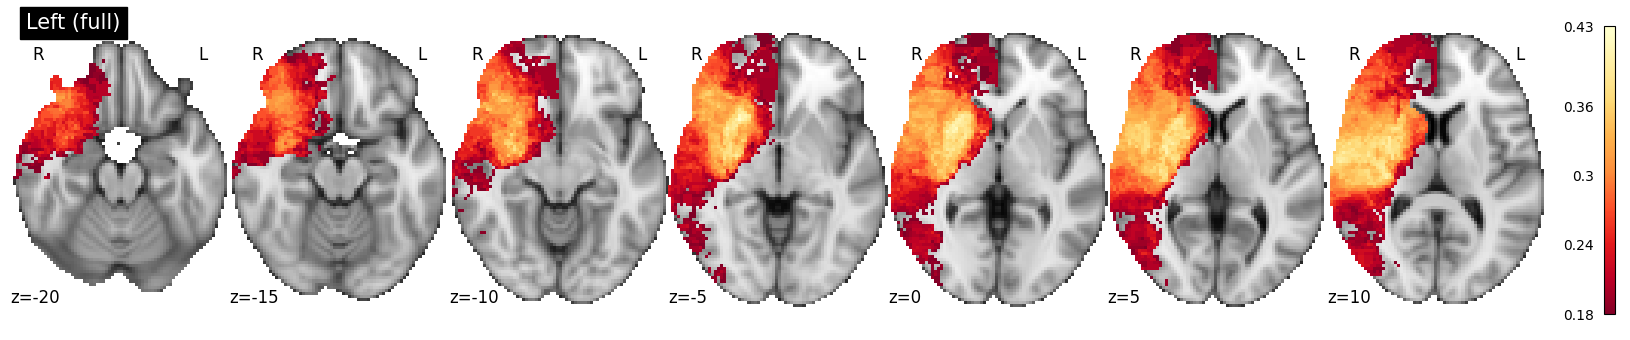

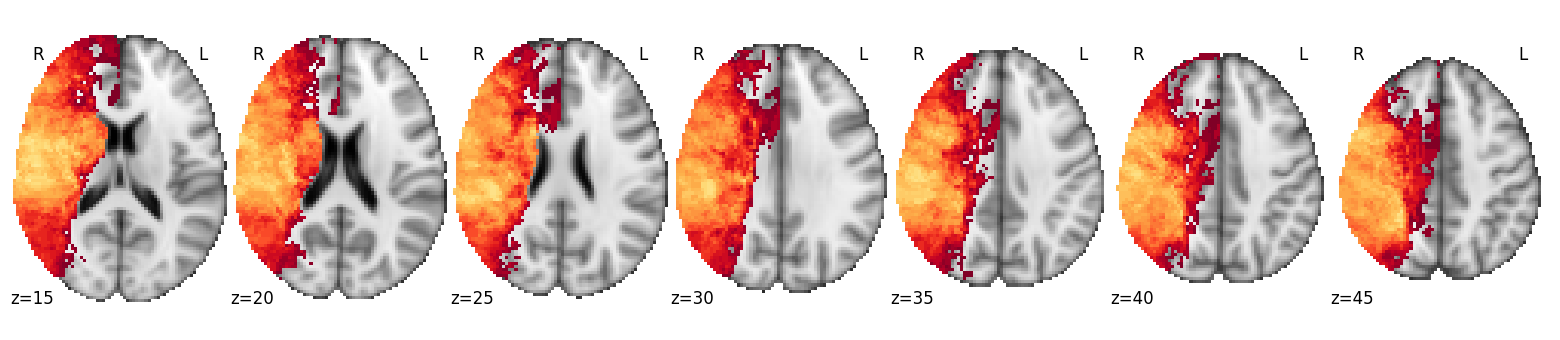

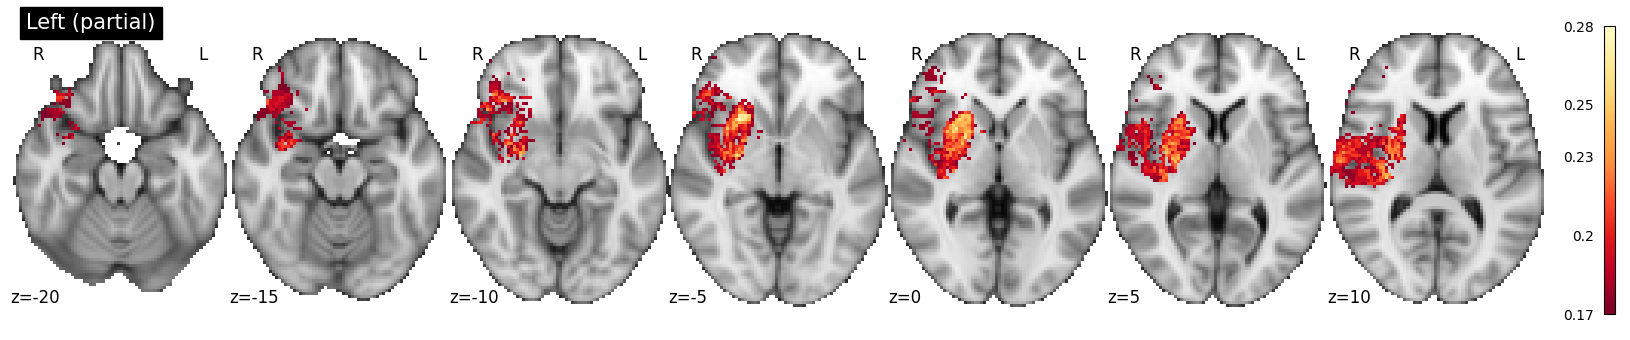

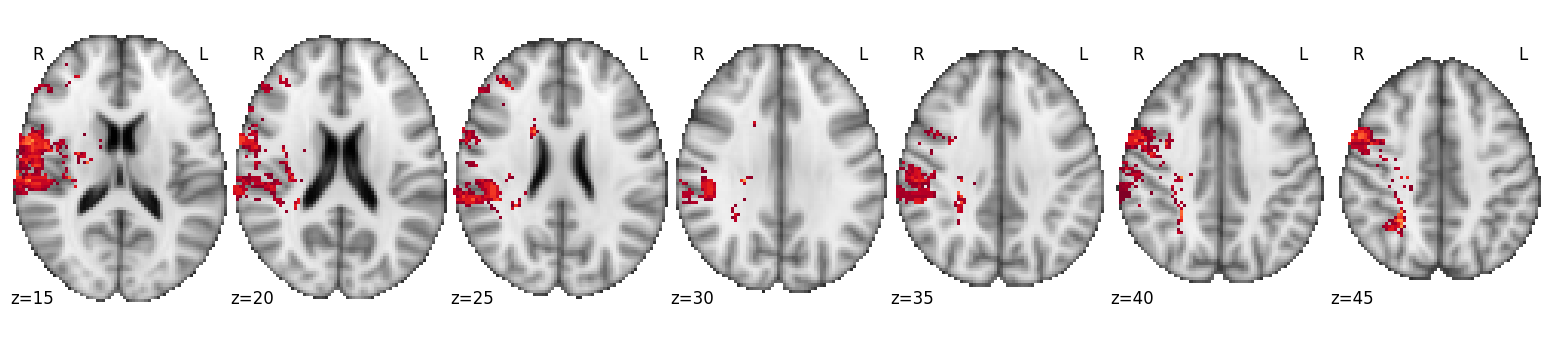

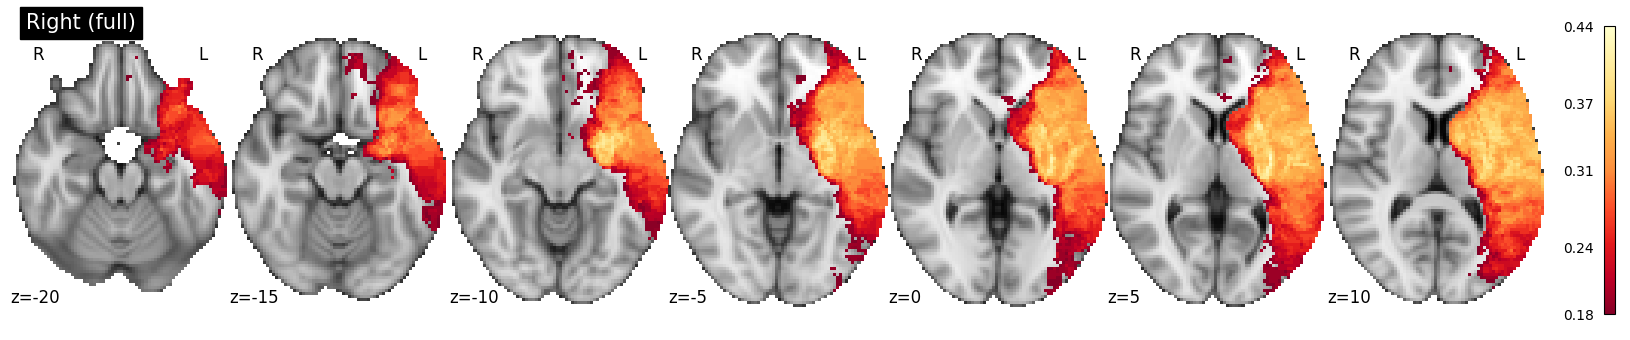

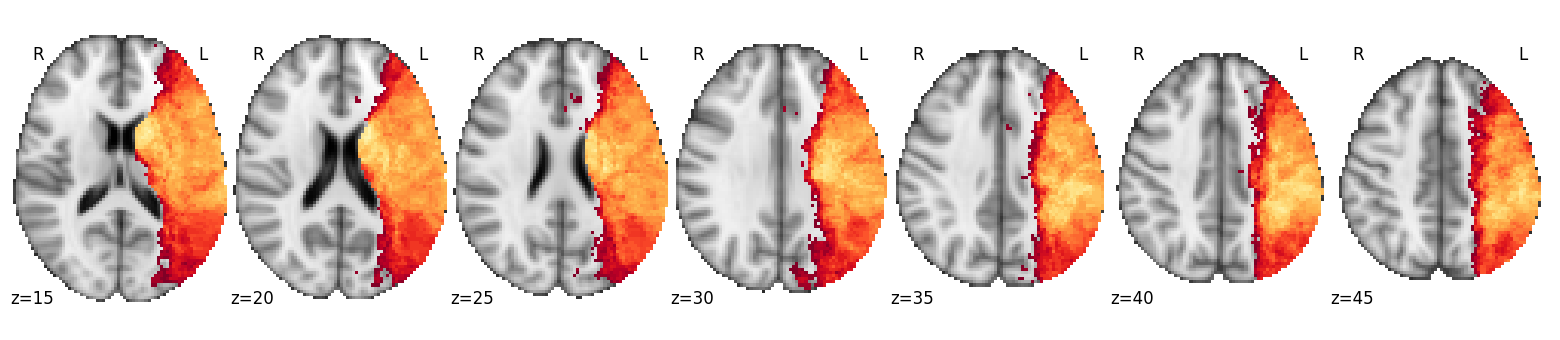

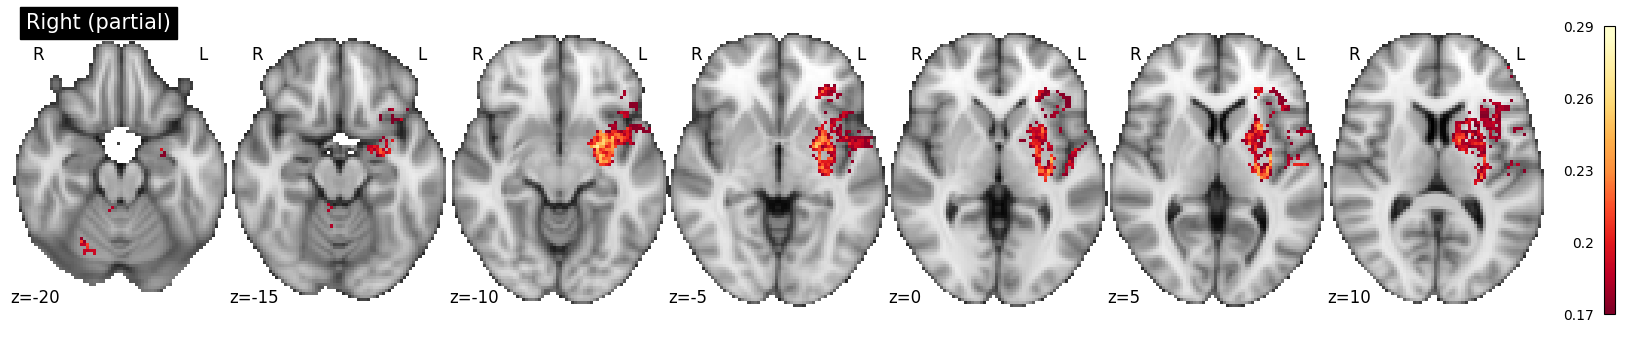

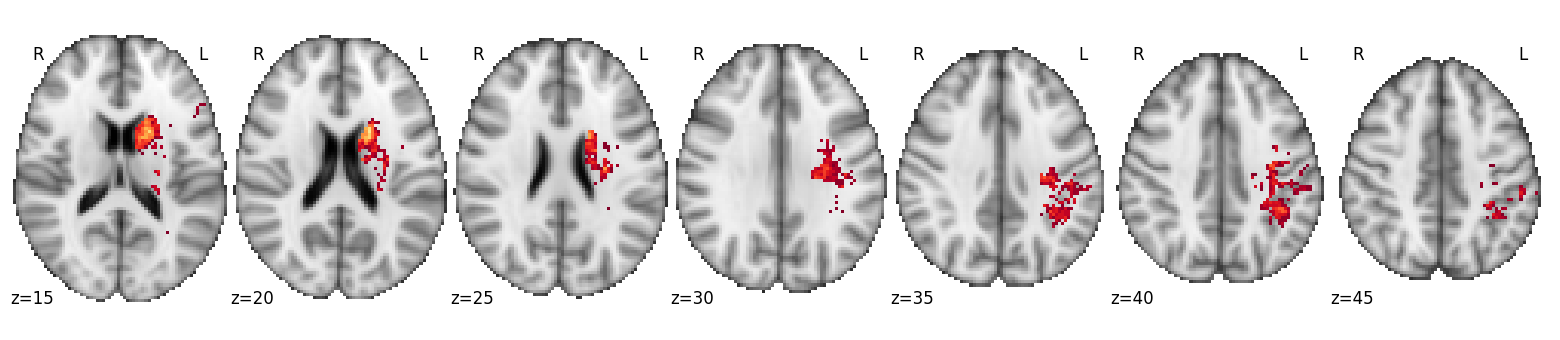

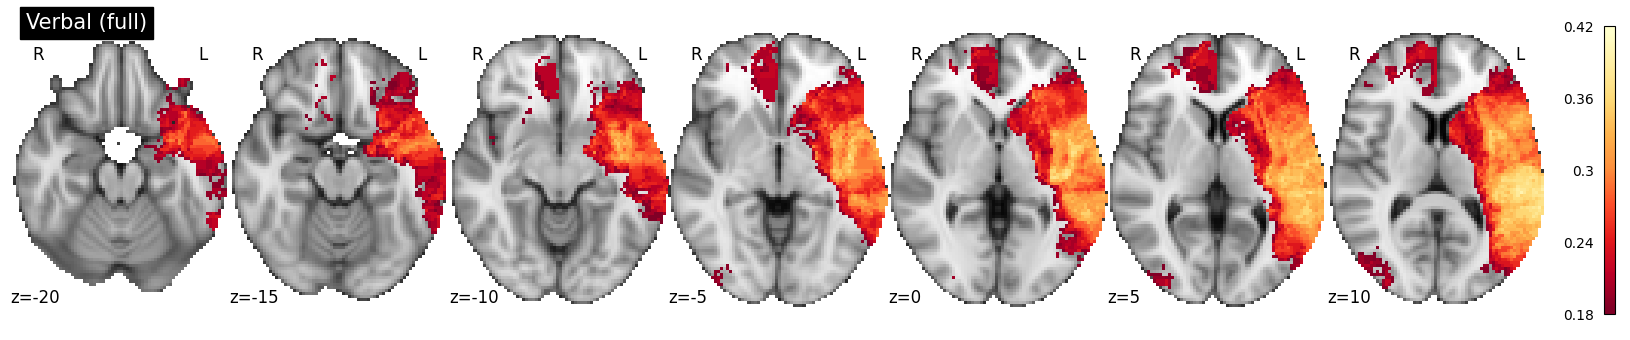

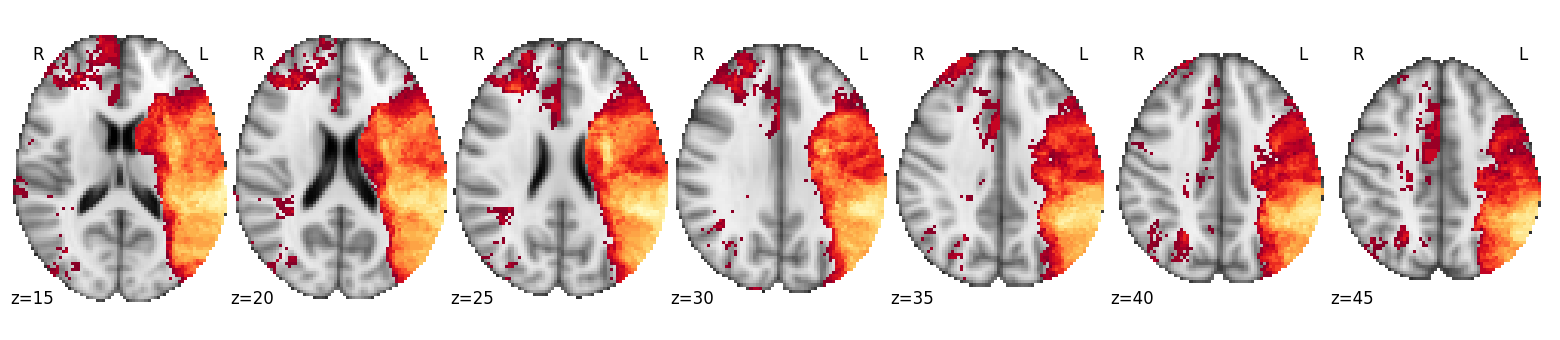

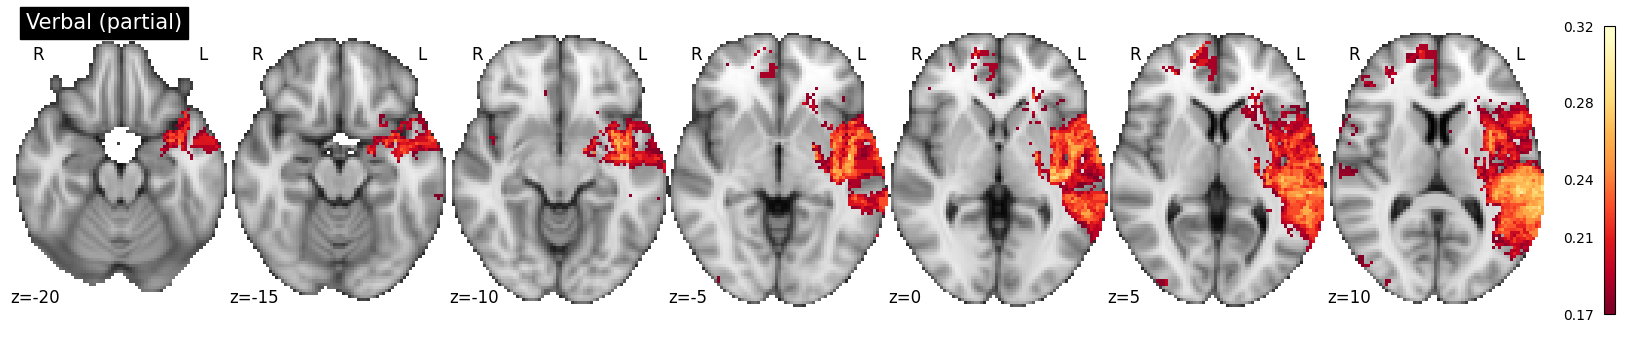

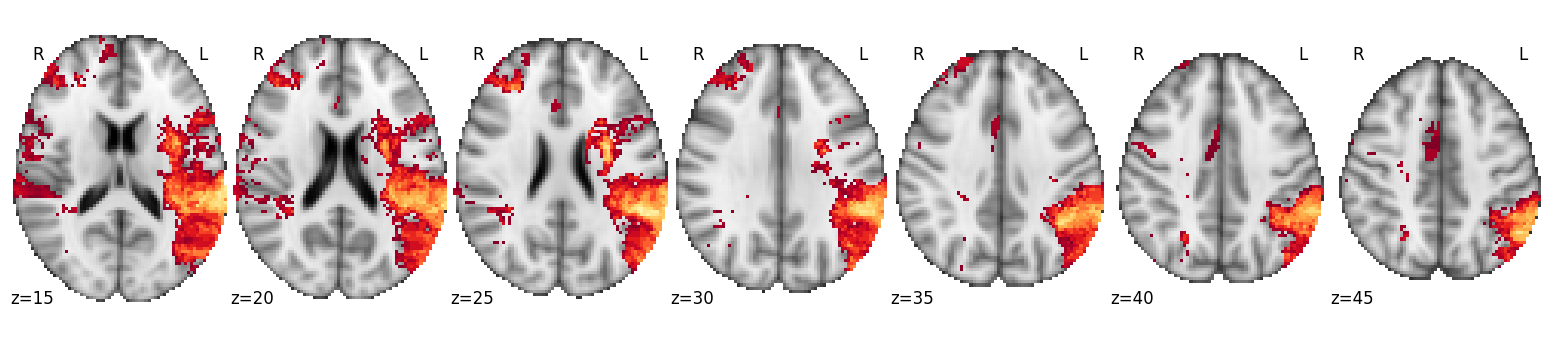

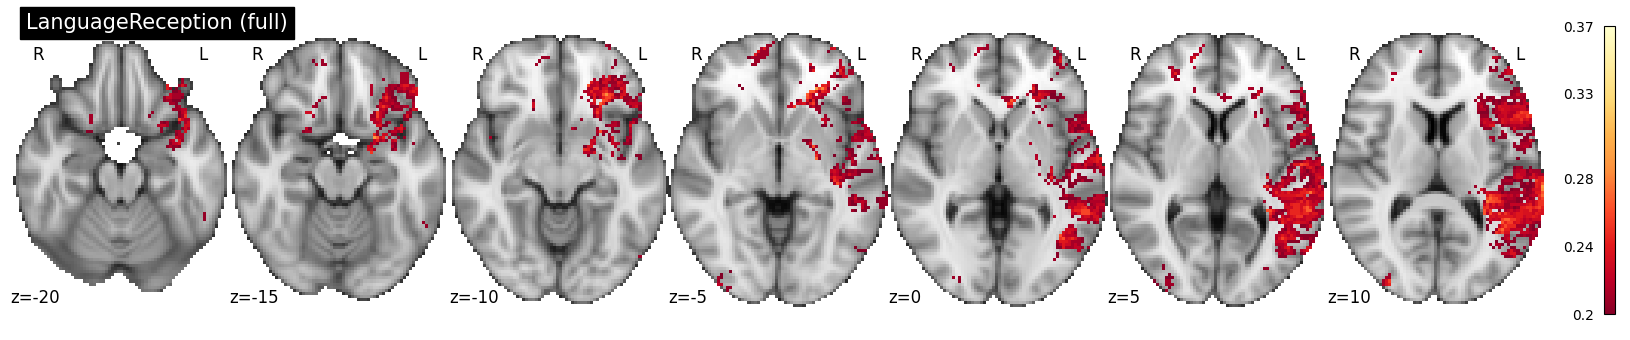

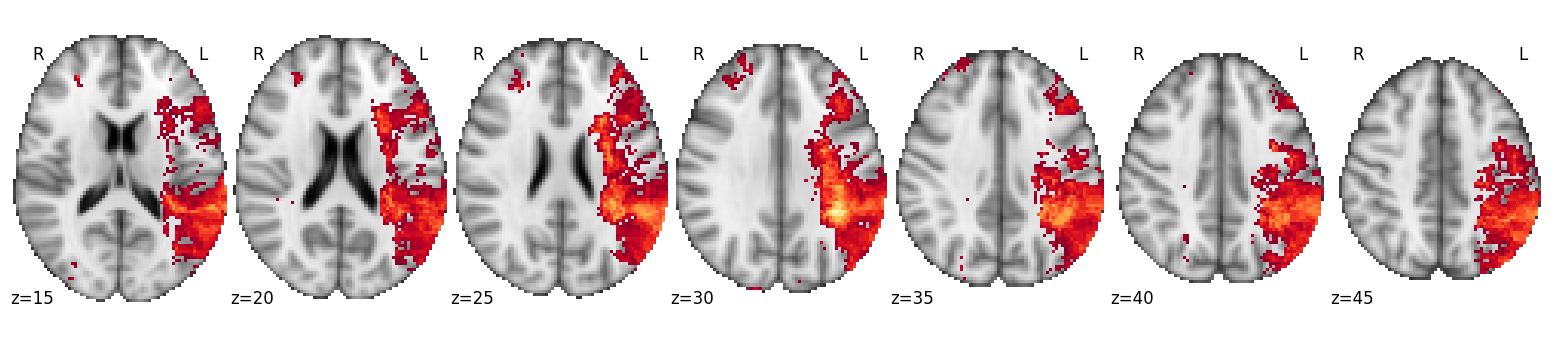

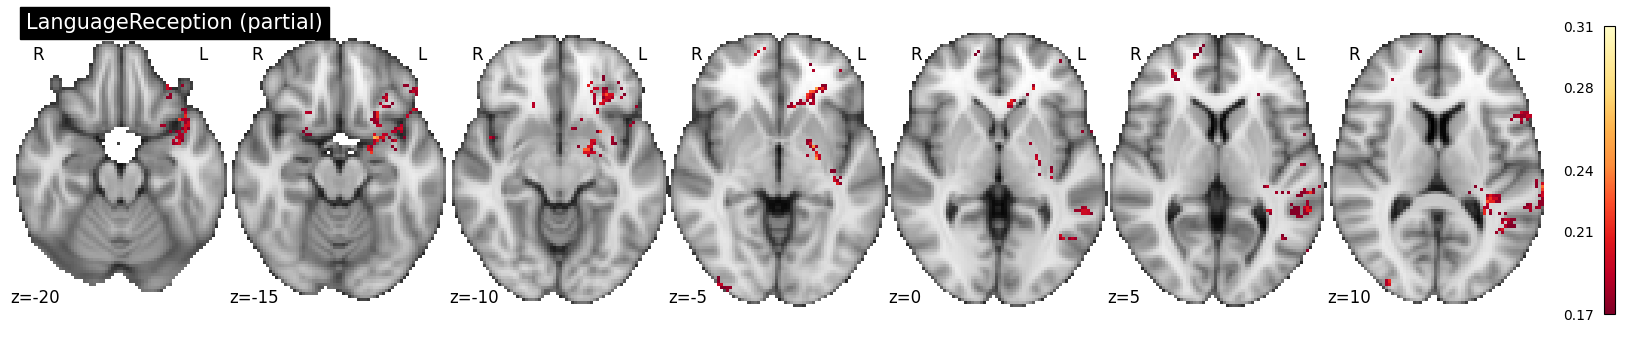

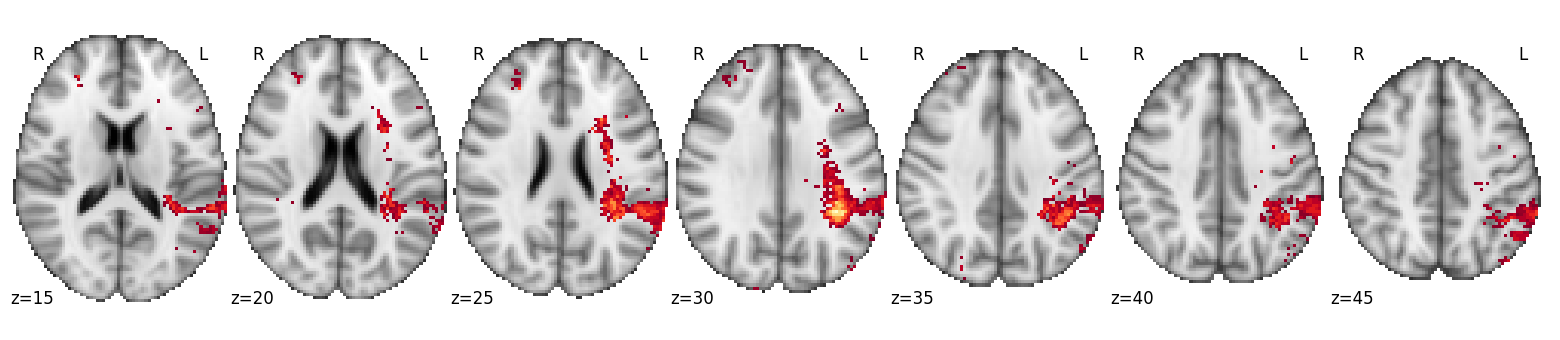

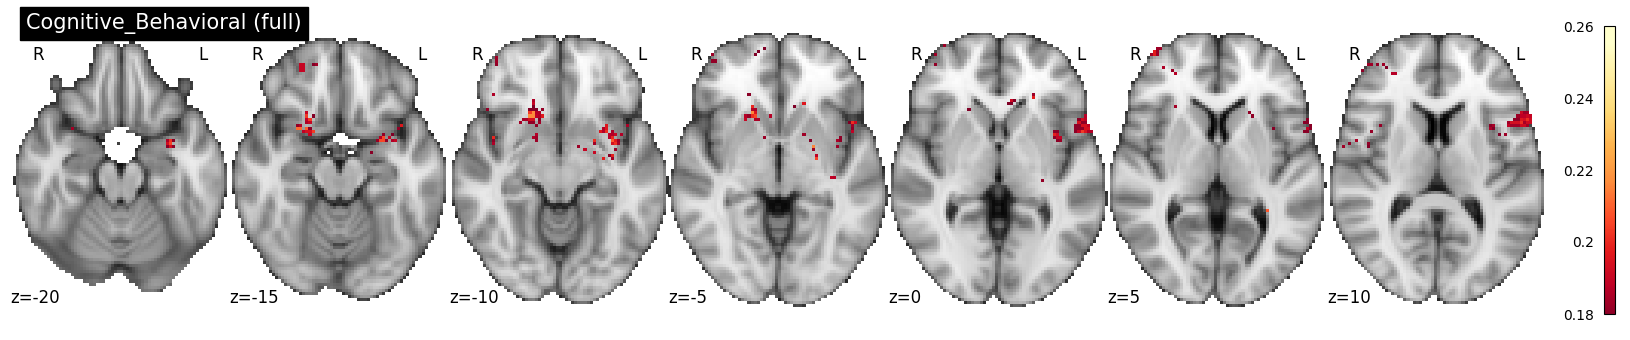

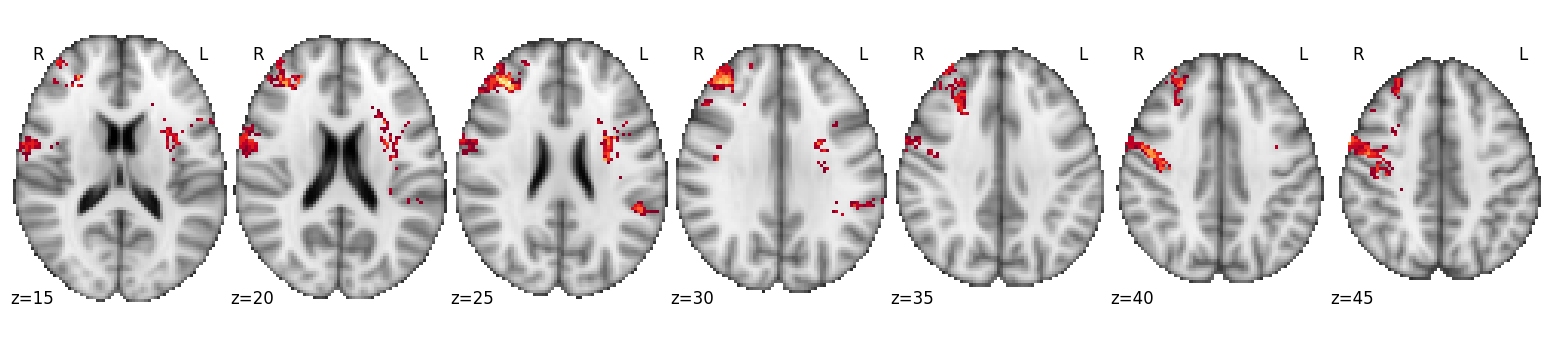

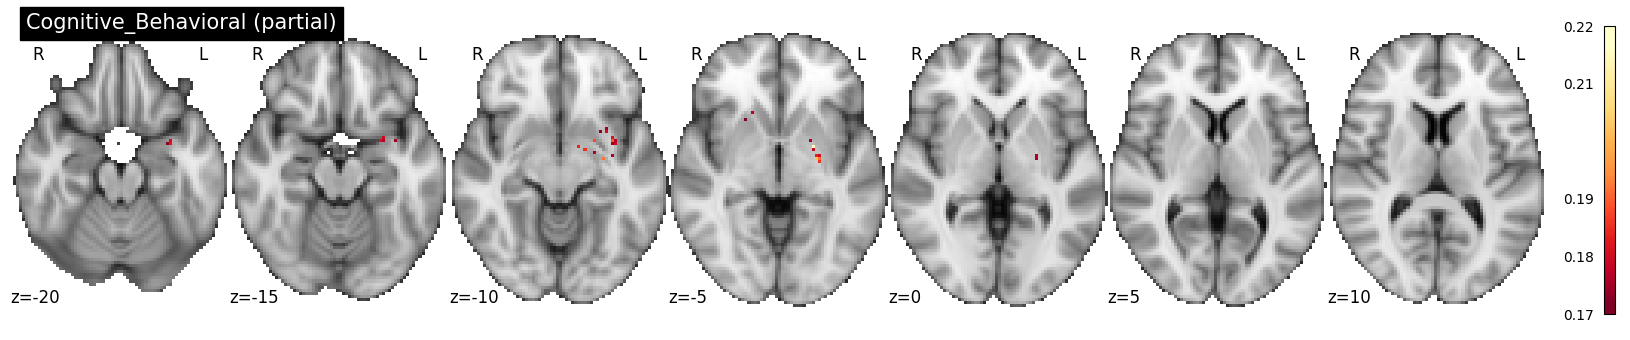

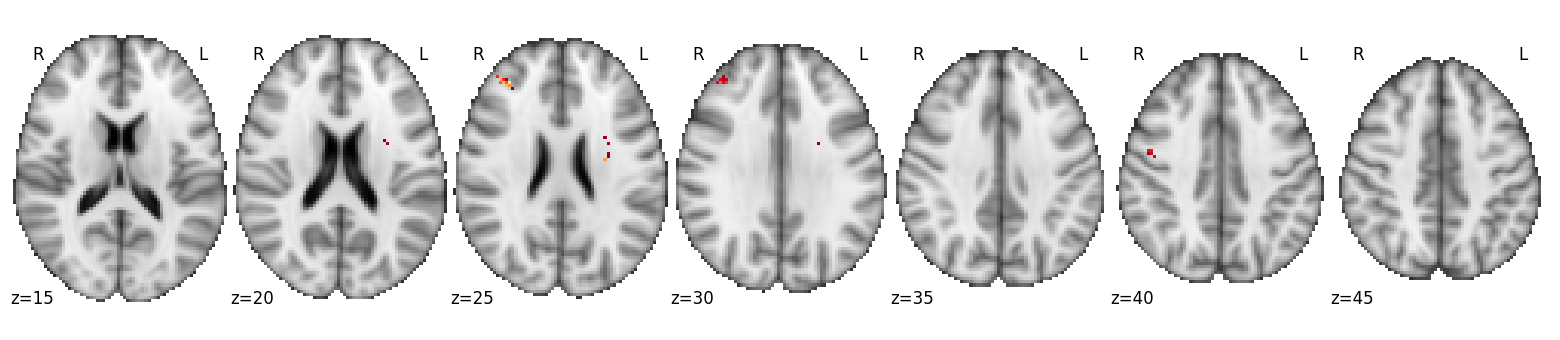

In [7]:
import nibabel as nib 
import numpy as np 
import pandas as pd
import os 
from nilearn import image
from nilearn.plotting import plot_stat_map, plot_glass_brain, plot_img
from atlasreader import create_output

# Data directory
data_dir = '/home/jcgriffis/LSS/boeslab/Users/jcgriffis/vips_psom_mapping/results_mapping_71626/min_stroke_0_min_test_0_min_interval_0.5_no_exc'

# Model
beh_list = ["contra_motor",  "Left", "Right", "Verbal", "LanguageReception", "Cognitive_Behavioral"]
v = "100"

# Plot map for each v threshold with effective FDR
for i, beh in enumerate(beh_list):
   
    # Load background
    bg_img = nib.load('/home/jcgriffis/LSS/boeslab/Atlas/volumetric/MNI152/2mm/MNI152_T1_2mm.nii.gz')
    img_data = bg_img.get_fdata()
    mask_img = nib.load('/home/jcgriffis/LSS/boeslab/Atlas/volumetric/MNI152/2mm/masks/wholecb_mask.nii.gz')
    mask_data = mask_img.get_fdata()
    img_data[np.isnan(img_data)==True] = 0
    img_data[mask_data == 0] = 0
    bg_img = nib.Nifti1Image(img_data, bg_img.affine)
    
    # Result folder 1
    result_dir1 = os.path.join(data_dir, beh, 'municorr_lesion_full_minfreq5', 'Permutation_Result_Images')
    
    # Load image
    my_img = nib.load(os.path.join(result_dir1, 'coeff_fwe05_vcrit_val_' + v + '.nii'))
    img_data = my_img.get_fdata()
    n_survive = sum(abs(np.ravel(img_data)) > 0)
    img_data[img_data < 0] = 0
    max_val = np.max((img_data[:]))
    min_val = np.min((img_data[:]))        
    my_img = nib.Nifti1Image(img_data, my_img.affine)
    my_img1 = nib.Nifti1Image(img_data, my_img.affine)

    # Plot first image
    my_cmap = 'YlOrRd_r'
    p1 = plot_img(my_img, bg_img=bg_img, cmap=my_cmap, threshold=0.01, colorbar=True,  vmax=max_val, display_mode='z', cut_coords=list(range(-20,15,5)), resampling_interpolation='continuous', radiological=True, black_bg=False, title=beh_list[i] + ' (full)')        
    p1 = plot_img(my_img, bg_img=bg_img, cmap=my_cmap, threshold=0.01, colorbar=False,  vmax=max_val, display_mode='z', cut_coords=list(range(15,50,5)), resampling_interpolation='continuous', radiological=True, black_bg=False)        
    print(beh_list[i] + ' : Full Correlation Effective FDR = ' + str(float(v) / n_survive)) # Effective FDR
    
    # Result folder 2
    result_dir2 = os.path.join(data_dir, beh, 'municorr_lesion_partial_minfreq5', 'Permutation_Result_Images')
    
    # Load image
    my_img = nib.load(os.path.join(result_dir2, 'coeff_fwe05_vcrit_val_' + v + '.nii'))
    img_data = my_img.get_fdata()
    n_survive = sum(abs(np.ravel(img_data)) > 0)
    img_data[img_data < 0] = 0
    max_val = np.max((img_data[:]))
    min_val = np.min((img_data[:]))        
    my_img = nib.Nifti1Image(img_data, my_img.affine)
    my_img2  = nib.Nifti1Image(img_data, my_img.affine)
    
    # Plot first image
    my_cmap = 'YlOrRd_r'
    p2 = plot_img(my_img, bg_img=bg_img, cmap=my_cmap, threshold=0.01, colorbar=True,  vmax=max_val, display_mode='z', cut_coords=list(range(-20,15,5)), resampling_interpolation='continuous', radiological=True, black_bg=False, title=beh_list[i] + ' (partial)')        
    p2 = plot_img(my_img, bg_img=bg_img, cmap=my_cmap, threshold=0.01, colorbar=False,  vmax=max_val, display_mode='z', cut_coords=list(range(15,50,5)), resampling_interpolation='continuous', radiological=True, black_bg=False)       
    print(beh_list[i] + ' : Partial Correlation Effective FDR = ' + str(float(v) / n_survive)) # Effective FDR
